# Hourly Crypto Algo-Trading - End-to-End Workflow

This notebook **calls the functions from the `.py` modules** in `src/` and shows
the complete workflow:

1. `src/download.py`  - pull hourly klines + funding rates (Binance) and
   macro series (Yahoo Finance), *incrementally*
2. `src/transform.py` - combine into one dataset, engineer 40 features, build targets
3. `src/train.py`     - tune LogReg / DecisionTree / RandomForest / XGBoost,
   pick a probability threshold on validation
4. `src/simulate.py`  - 4 vector strategies + 1 exact iterative simulation
   (reinvestment), benchmark vs buy-and-hold BTC, rolling returns
5. Show the **latest new trades**
6. `src/monitor.py`   - health summary / Telegram push (bonus)
7. `src/broker.py`    - build broker orders from the trade list, dry-run (bonus)

Two modes (rubric: two regimes for the system):
- **file mode** (default): runs from local parquet files - fast, reproducible
- **download mode**: first refreshes data from the APIs (used by the daily cron job)

In [1]:
%matplotlib inline
import sys
from pathlib import Path

# make the project root importable when the notebook runs from notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    sys.path.insert(0, str(ROOT.parent))
    ROOT = ROOT.parent

import pandas as pd
from src import config, pipeline

pd.set_option("display.width", 140)
print("project root:", config.PROJECT_DIR)

project root: E:\GitHub\stock-markets-analytics-zoomcamp\projects\hourly-crypto


## 1. Download / refresh data (Binance + Yahoo, incremental)

`download.main` fetches only rows newer than what is already stored
(~30 s when up to date; a fresh clone pulls the full 2021-2026 history,
~15-30 min). Safe to call on every run - that is what the cron job does.

In [2]:
from src import download

pipeline._run(download.main, ["src.download"])

macro: 1474 daily rows (SPY/VIX/DXY)


universe: 42 symbols, dropped (delisted): ['TONUSDT', 'EOSUSDT', 'MKRUSDT']


[01/42] BTCUSDT: +4 klines, +0 funding (1s)


[02/42] ETHUSDT: +4 klines, +0 funding (1s)


[03/42] BNBUSDT: +4 klines, +0 funding (2s)


[04/42] SOLUSDT: +4 klines, +0 funding (3s)


... (35 outputs left out)

[40/42] 1000PEPEUSDT: +4 klines, +0 funding (26s)


[41/42] 1000SHIBUSDT: +4 klines, +0 funding (26s)


[42/42] WIFUSDT: +4 klines, +1 funding (27s)


done in 27s -> E:\GitHub\stock-markets-analytics-zoomcamp\projects\hourly-crypto\data\raw


## 2. Run the full pipeline (file mode)

`pipeline.run` executes transform -> train -> simulate(valid, for strategy
selection) -> simulate(test) -> latest trades. Combined with step 1 this is the
full end-to-end workflow: **download, transform, predict, simulate, latest trades**.

In [3]:
# full end-to-end run (train takes ~10 minutes the first time)
pipeline.run(source="file")

[pipeline] source=file: using local data (no API calls)


loaded 1,865,216 rows / 42 symbols (3s)


combined: 1,865,216 rows x 53 cols (16s)



saved -> E:\GitHub\stock-markets-analytics-zoomcamp\projects\hourly-crypto\data\combined.parquet
window: 2021-01-01 00:00:00+00:00 .. 2026-11-15 15:00:00+00:00
features: 40 numeric + dummies ['symbol', 'hour_bucket']
target target_24h (growth>1.0): train class share = 0.494, all = 0.486
rows with target = 1,864,208 / 1,865,216


rows: train=965,141 valid=367,887 test=505,680 | features=92


tuning logreg...


... (17 outputs left out)

sim3_rf_longs: {'total_return': 0.5306, 'cagr': 0.3633, 'sharpe': 0.804, 'max_drawdown': -0.4334, 'n_trades': 42, 'trades_per_day': 0.08}


sim4_rf_advanced: {'total_return': 0.0881, 'cagr': 0.0634, 'sharpe': 0.355, 'max_drawdown': -0.3823, 'n_trades': 185, 'trades_per_day': 0.37}


sim5_rf_exact {'stop_loss': None, 'max_hold': None, 'regime_min': 0.0178002822079937}: {'total_return': -0.1097, 'cagr': -0.0811, 'sharpe': -0.164, 'max_drawdown': -0.3762, 'n_trades': 137, 'trades_per_day': 0.27}
benchmark_btc: {'total_return': -0.3877, 'cagr': -0.3003, 'sharpe': -0.665, 'max_drawdown': -0.5377, 'n_trades': 1, 'trades_per_day': 0.0}



wrote simulation_results_test.csv, equity curves, trades, ticker precision

latest trades @ 2026-11-14 15:00:00+00:00 (0 signals) -> outputs/latest_trades.csv

=== test-set strategy summary ===
                   total_return    cagr  sharpe  max_drawdown  n_trades  trades_per_day
sim1_rf_long             0.1248  0.0894   0.438       -0.3829     382.0            0.76
sim2_rf_probasize        0.1249  0.0894   0.438       -0.3830     382.0            0.76
sim3_rf_longs            0.5306  0.3633   0.804       -0.4334      42.0            0.08
sim4_rf_advanced         0.0881  0.0634   0.355       -0.3823     185.0            0.37
sim5_rf_exact           -0.1097 -0.0811  -0.164       -0.3762     137.0            0.27
benchmark_btc           -0.3877 -0.3003  -0.665       -0.5377       1.0            0.00

[pipeline] done in 853s


## 3. Strategy results

In [4]:
res_test = pd.read_csv(config.OUTPUT_DIR / "simulation_results_test.csv", index_col=0)
res_valid = pd.read_csv(config.OUTPUT_DIR / "simulation_results_valid.csv", index_col=0)
print("VALID  (2024-07 .. 2025-07)")
display(res_valid)
print("TEST   (2025-07 .. 2026-11)")
display(res_test)

VALID  (2024-07 .. 2025-07)


,total_return,cagr,sharpe,max_drawdown,n_trades,trades_per_day
sim1_rf_long,0.7025,0.7031,1.274,-0.2743,357.0,0.98
sim2_rf_probasize,0.7058,0.7064,1.278,-0.2745,357.0,0.98
sim3_rf_longs,0.0345,0.0346,0.444,-0.6839,43.0,0.12
sim4_rf_advanced,0.8510,0.8517,1.426,-0.3045,144.0,0.39
sim5_rf_exact,0.8558,0.8566,1.629,-0.2863,122.0,0.33
benchmark_btc,0.7018,0.7025,1.295,-0.3097,1.0,0.00


TEST   (2025-07 .. 2026-11)


,total_return,cagr,sharpe,max_drawdown,n_trades,trades_per_day
sim1_rf_long,0.1248,0.0894,0.438,-0.3829,382.0,0.76
sim2_rf_probasize,0.1249,0.0894,0.438,-0.3830,382.0,0.76
sim3_rf_longs,0.5306,0.3633,0.804,-0.4334,42.0,0.08
sim4_rf_advanced,0.0881,0.0634,0.355,-0.3823,185.0,0.37
sim5_rf_exact,-0.1097,-0.0811,-0.164,-0.3762,137.0,0.27
benchmark_btc,-0.3877,-0.3003,-0.665,-0.5377,1.0,0.00


In [5]:
import json
with open(config.OUTPUT_DIR / "metrics.json") as f:
    metrics = json.load(f)
rows = {k: {"val_auc": v["val_auc"], "test_auc": v["test_auc"],
            "threshold": v["threshold"], "val_precision": v["val_precision"],
            "test_precision": v["test_precision"],
            "test_signal_share": v["test_signal_share"]}
        for k, v in metrics["models"].items()}
pd.DataFrame(rows).T

,val_auc,test_auc,threshold,val_precision,test_precision,test_signal_share
logreg,0.507155,0.512102,0.50,0.532712,0.484371,0.020940
dt,0.515441,0.507556,0.67,0.513533,0.469826,0.405385
rf,0.523995,0.528785,0.65,0.619391,0.599415,0.020976
xgb,0.523581,0.524534,0.80,0.547812,0.543593,0.046838


## 4. Equity curves & rolling returns vs buy-and-hold BTC (test set)

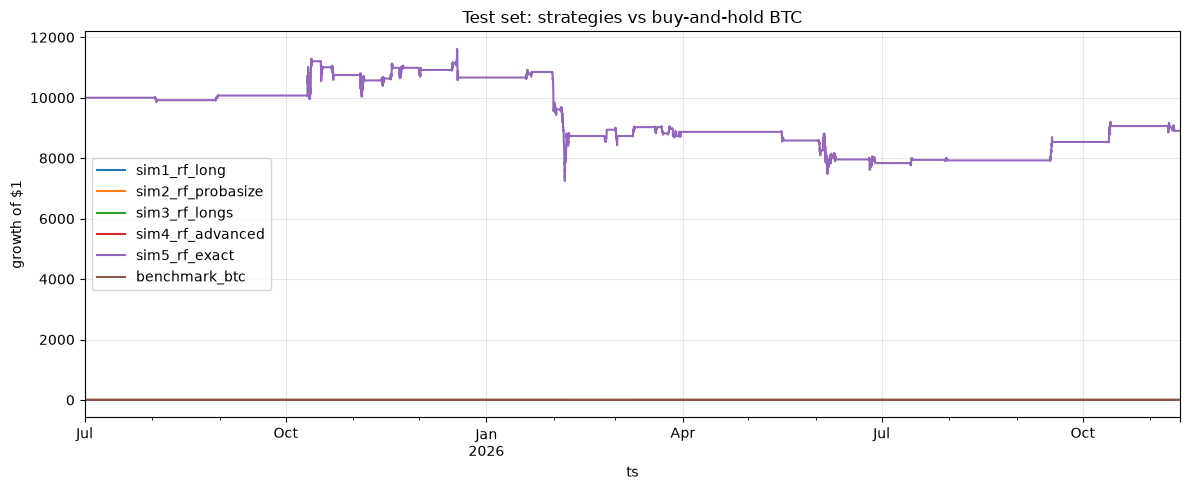

In [6]:
import matplotlib.pyplot as plt

eq = pd.read_parquet(config.OUTPUT_DIR / "equity_curves_test.parquet")
ax = eq.plot(figsize=(12, 5), title="Test set: strategies vs buy-and-hold BTC")
ax.set_ylabel("growth of $1")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

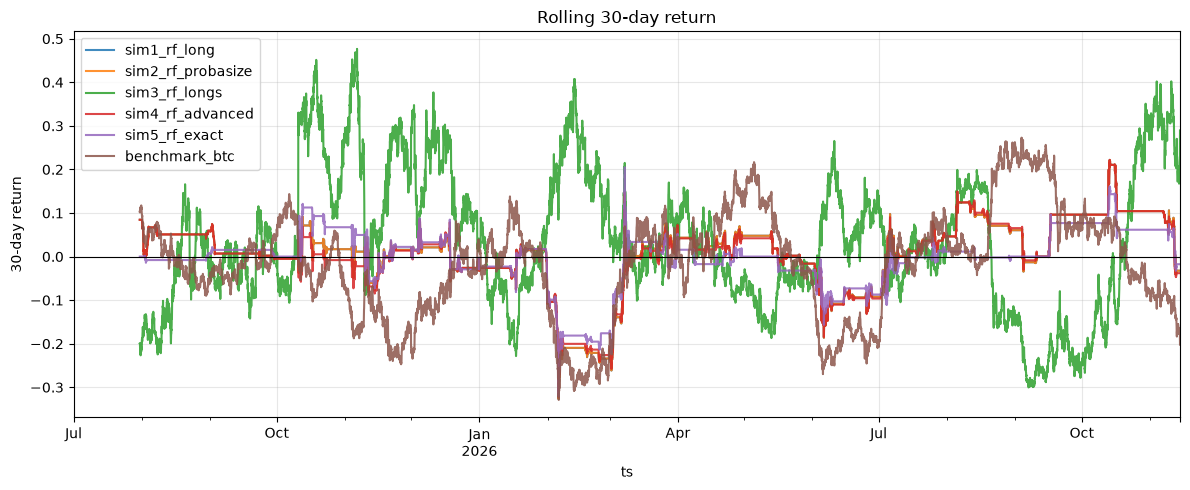

rolling 30d return stats:


,mean,min,max
sim1_rf_long,0.008,-0.327,0.222
sim2_rf_probasize,0.008,-0.327,0.222
sim3_rf_longs,0.037,-0.300,0.477
sim4_rf_advanced,0.006,-0.323,0.222
sim5_rf_exact,-0.004,-0.321,0.205
benchmark_btc,-0.017,-0.329,0.273


In [7]:
# rolling 30-day returns (hourly equity curve -> 720h windows)
roll = eq / eq.shift(30 * 24) - 1
ax = roll.plot(figsize=(12, 5), title="Rolling 30-day return", alpha=0.85)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("30-day return")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("rolling 30d return stats:")
display(roll.agg(["mean", "min", "max"]).T.round(3))

## 5. Latest new trades (what to execute now)

Empty means no probability cleared the 0.65 threshold this hour - normal at a
~2% signal share.

In [8]:
pd.read_csv(config.OUTPUT_DIR / "latest_trades.csv")

,ts,symbol,signal_probability,action


## 6. Monitoring (bonus): one-command health summary

`python -m src.monitor --telegram` prints these numbers, writes
`outputs/monitor.html` and (when `TELEGRAM_BOT_TOKEN`/`TELEGRAM_CHAT_ID` are
set) pushes them to Telegram - run it from cron right after the pipeline to
monitor model quality, data freshness and portfolio results live.

In [9]:
from src import monitor

s = monitor.summary()
print("wrote", monitor.write_html(s))
pd.Series(s, name="value")

wrote E:\GitHub\stock-markets-analytics-zoomcamp\projects\hourly-crypto\outputs\monitor.html


updated_utc                        2026-11-15 15:47
data_latest_hour          2026-11-14 15:00:00+00:00
rf_test_auc                                  0.5288
rf_threshold                                   0.65
rf_test_precision                            0.5994
open_signals_now                                  0
test_total_return                           -0.1097
test_sharpe                                   -0.16
test_max_drawdown                           -0.3762
benchmark_total_return                      -0.3877
Name: value, dtype: object

## 7. Broker orders (bonus): trade list -> orders (dry run)

`preview()` converts the latest signals into market orders and writes
`outputs/orders_latest.json`. `python -m src.broker --live --testnet`
actually places them (keys from env vars); default is always a dry run.

In [10]:
from src import broker

orders = broker.preview(budget_usdt=500)
orders

[broker] 0 order(s), budget 500 USDT each -> orders_latest.json (dry run)
[broker] no open signals this hour - nothing to do


,symbol,side,type,quoteOrderQty,signal_probability


## 8. EDA - target and feature/target correlations

target_24h base rate: 0.486 | rows: 1,865,216 | symbols: 42


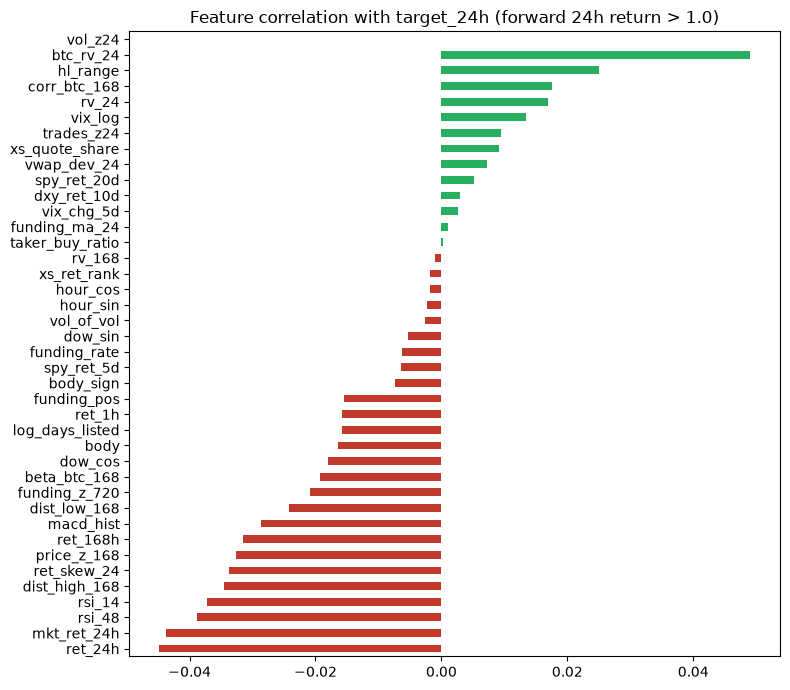

,corr_with_target,target_24h
ret_24h,-0.044859,NaN
mkt_ret_24h,-0.043779,NaN
rsi_48,-0.038796,NaN
rsi_14,-0.037242,NaN
dist_high_168,-0.034538,NaN
ret_skew_24,-0.033671,NaN
price_z_168,-0.032703,NaN
ret_168h,-0.031588,NaN


In [11]:
df = pd.read_parquet(config.DATA_DIR / "combined.parquet")
print("target_24h base rate:", round(df["target_24h"].mean(), 3),
      "| rows:", f"{len(df):,}", "| symbols:", df["symbol"].nunique())

from src.transform import NUMERIC_FEATURES, TARGET
corr = df[NUMERIC_FEATURES + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
corr.plot(kind="barh", ax=ax, color=["#c0392b" if v < 0 else "#27ae60" for v in corr])
ax.set_title("Feature correlation with target_24h (forward 24h return > 1.0)")
plt.tight_layout()
plt.show()
pd.DataFrame({"corr_with_target": corr}).head(8).join(
    corr.tail(8), lsuffix="_low", rsuffix="_high")

## 9. Deep analysis: precision by ticker (debug wrong predictions)

,n_rows,base_rate,signal_share,precision
symbol,,,,
JUPUSDT,12040.0,0.481229,0.004319,0.884615
WIFUSDT,12040.0,0.459551,0.008887,0.803738
DOGEUSDT,12040.0,0.467857,0.024834,0.698997
1000PEPEUSDT,12040.0,0.466445,0.010880,0.687023
ENAUSDT,12040.0,0.447259,0.009718,0.683761
RUNEUSDT,12040.0,0.482475,0.022841,0.672727
UNIUSDT,12040.0,0.483804,0.022259,0.660448
LDOUSDT,12040.0,0.483223,0.013372,0.658385


,n_rows,base_rate,signal_share,precision
symbol,,,,
TIAUSDT,12040.0,0.465947,0.010880,0.534351
BTCUSDT,12040.0,0.503904,0.032807,0.526582
DOTUSDT,12040.0,0.446262,0.025997,0.520767
OPUSDT,12040.0,0.467940,0.024419,0.500000
SOLUSDT,12040.0,0.491611,0.029485,0.461972


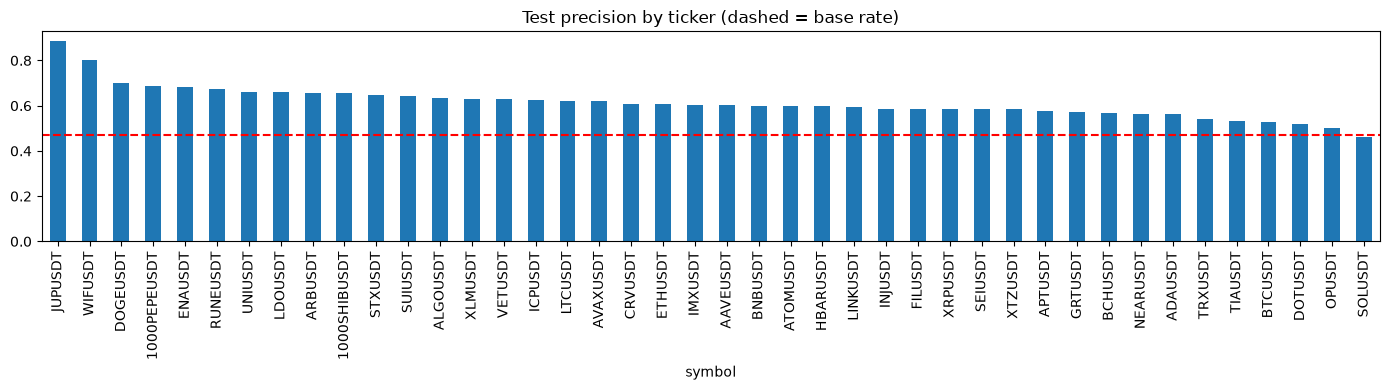

In [12]:
tick = pd.read_csv(config.OUTPUT_DIR / "ticker_precision_test.csv", index_col=0)
tick = tick.sort_values("precision", ascending=False)
display(tick.head(8))
display(tick.tail(5))
ax = tick["precision"].dropna().plot(kind="bar", figsize=(14, 4),
                                     title="Test precision by ticker (dashed = base rate)")
ax.axhline(tick["base_rate"].mean(), color="red", ls="--")
plt.tight_layout()
plt.show()

## 10. Feature importance (tree models)

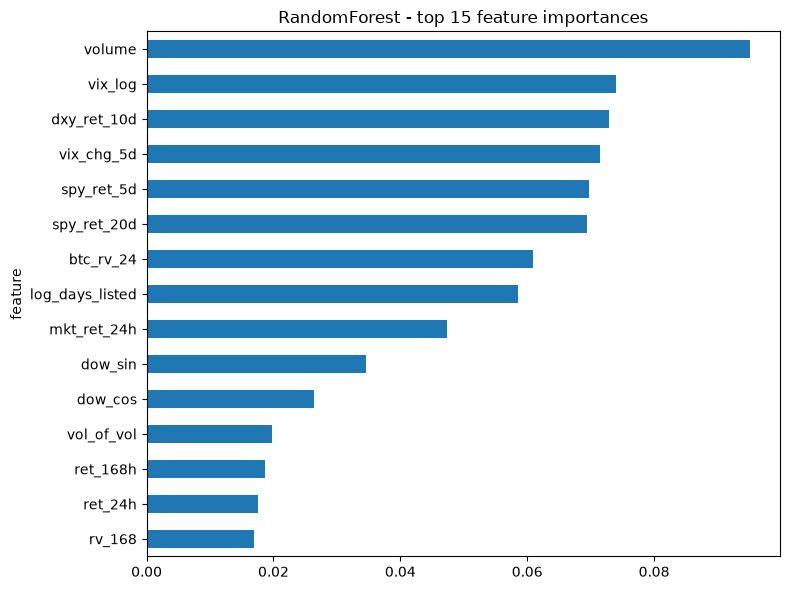

In [13]:
imp = pd.read_csv(config.OUTPUT_DIR / "feature_importance.csv")
imp = imp[imp["model"] == "rf"].nlargest(15, "importance")
ax = imp.iloc[::-1].plot(x="feature", y="importance", kind="barh",
                         legend=False, figsize=(8, 6),
                         title="RandomForest - top 15 feature importances")
plt.tight_layout()
plt.show()

## 11. Signal economics (the key debugging finding)

The signal is positive-EV per trade, but **hourly re-weighting churned the
portfolio to death in fees**. All deployed strategies therefore decide once a
day (00:00 UTC) and hold for 24h.

In [14]:
p = pd.read_parquet(config.OUTPUT_DIR / "predictions_with_sims_test.parquet")
g = pd.read_parquet(config.DATA_DIR / "combined.parquet",
                    columns=["ts", "symbol", "growth_future_24h"])
p = p.merge(g, on=["ts", "symbol"], how="left")
thr = metrics["models"]["rf"]["threshold"]
sig = p[f"proba_rf"] >= thr
fwd = p["growth_future_24h"] - 1
pd.DataFrame({
    "n_signals": [int(sig.sum())],
    "share_of_rows": [round(sig.mean(), 4)],
    "mean_fwd24h_signal_%": [round(fwd[sig].mean() * 100, 3)],
    "mean_fwd24h_nosignal_%": [round(fwd[~sig].mean() * 100, 3)],
    "winrate_signal": [round((fwd[sig] > 0).mean(), 3)],
    "ev_after_costs_%": [round(fwd[sig].mean() * 100 - 0.30, 3)],
})

,n_signals,share_of_rows,mean_fwd24h_signal_%,mean_fwd24h_nosignal_%,winrate_signal,ev_after_costs_%
0,10607,0.021,1.161,-0.119,0.599,0.861
